# ML-10 — Content Action Playbook

**Purpose:** turn the Week-6 client-grouped validation exercise into a *human-reviewed* content triage queue and a reusable paper figure.

**Decision boundary:** this is a research prototype using one anonymized snapshot. Scores rank pages for review; they do **not** establish that a page will decline in the future, that a refresh will improve outcomes, or that the same ranking will work in production.

**Reproducibility:** this notebook retrains the same Random Forest pipeline and client-grouped split used in `w06_validation_audit.ipynb`. The queue is generated from the grouped holdout only. Actual labels are used for evaluation and descriptive analysis, never as queue features or exported queue columns.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
REPO_URL = "https://github.com/Kifayat-Sayed/kifayat-flyrank-ml-internship.git"
DATA_CANDIDATES = [
    Path("data/raw/content_refresh_anonymized.csv"),
    Path("content_refresh_anonymized.csv"),
    Path("/mnt/data/content_refresh_anonymized.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Run from the repository root containing "
        "data/raw/content_refresh_anonymized.csv, or place the CSV beside this notebook."
    )
data = pd.read_csv(DATA_PATH)
required = {"content_id", "client_id", "trend_direction", "trend_pct",
            "days_since_last_update", "impressions_90d"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Dataset missing required columns: {sorted(missing)}")
data["is_declining_label"] = data["trend_direction"].eq("down").astype(int)
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data/raw/content_refresh_anonymized.csv").exists() and DATA_PATH.parent == Path("/mnt/data"):
    REPO_ROOT = Path("/mnt/data")
OUTPUT_DIR = REPO_ROOT / "work" / "outputs"
FIGURE_DIR = REPO_ROOT / "work" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Dataset: {DATA_PATH} | rows={len(data):,} | clients={data['client_id'].nunique()}")
print(f"Observed decline-label prevalence: {data['is_declining_label'].mean():.1%}")
print(f"Exports will be written to: {OUTPUT_DIR} and {FIGURE_DIR}")

Dataset: content_refresh_anonymized.csv | rows=30,000 | clients=32
Observed decline-label prevalence: 54.2%
Exports will be written to: /mnt/data/work/outputs and /mnt/data/work/figures


## 1. Ranked actions + reason codes

### How to read the queue

The Random Forest score is used **only to rank review priority**. The reason codes below are transparent rules based on snapshot fields, not SHAP explanations and not causal attributions. They provide a reviewer with a starting point to investigate:

- `DECAY_SIGNAL`: the observed label is associated with a downward recent trend in this snapshot; this is not a forecast guarantee.
- `STALE_HIGH_VALUE`: page has not been updated recently and has at least 3,000 impressions in the trailing 90-day aggregate; inspect before proposing a refresh.
- `POSITION_OPPORTUNITY`: average position is in a configurable review band (8–20); inspect search intent, SERP changes and snippet quality.
- `LOW_ENGAGEMENT`: engagement rate is below the dataset's median; confirm metric definition and tracking before interpreting.
- `LOW_EVIDENCE`: little exposure (under 100 trailing-90-day impressions) means evidence may be too thin for a confident content decision.

Dataset interpretation guardrails: `ctr`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`, and `trend_pct` are percentage-scaled values (for example, `ctr = 0.76` means 0.76%, not 76%). `avg_position = 0` means no data and must not be read as rank zero. The top-ranked rows are not automatic work orders. Archetypes are assigned by explicit, reviewable rules and mapped to suggested *investigation* actions. Missing or conflicting signals should result in manual review, not a forced recommendation.

In [2]:
TARGET = "is_declining_label"
EXCLUDED = {
    "content_id", "client_id", TARGET, "trend_direction", "trend_pct",
    "impressions_last_30d", "impressions_prev_30d",
    "clicks_last_30d", "clicks_prev_30d",
    "sessions_last_30d", "sessions_prev_30d",
    "provider_used", "model_used"
}
feature_cols = [c for c in data.columns if c not in EXCLUDED and not data[c].isna().all()]
X = data[feature_cols].copy()
y = data[TARGET].astype(int)
groups = data["client_id"]
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

def make_model():
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True))])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
    ])
    prep = ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])
    return Pipeline([("preprocess", prep), ("classifier", RandomForestClassifier(
        n_estimators=120, min_samples_leaf=5, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED
    ))])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, review_idx = next(splitter.split(X, y, groups=groups))
train_clients = set(groups.iloc[train_idx])
review_clients = set(groups.iloc[review_idx])
assert train_clients.isdisjoint(review_clients), "Client overlap detected."
model = make_model()
model.fit(X.iloc[train_idx], y.iloc[train_idx])
review_scores = model.predict_proba(X.iloc[review_idx])[:, 1]
review_rows = data.iloc[review_idx].copy().reset_index(drop=True)
review_rows["model_review_score"] = review_scores
review_rows["observed_label_for_evaluation_only"] = y.iloc[review_idx].to_numpy()
print(f"Training: {len(train_idx):,} rows / {len(train_clients)} clients")
print(f"Review holdout: {len(review_idx):,} rows / {len(review_clients)} unseen clients")
print(f"Client overlap: {len(train_clients & review_clients)}")

Training: 23,837 rows / 25 clients
Review holdout: 6,163 rows / 7 unseen clients
Client overlap: 0


In [3]:
def num_col(frame, name, default=np.nan):
    if name not in frame.columns:
        return pd.Series(default, index=frame.index, dtype="float64")
    return pd.to_numeric(frame[name], errors="coerce")

def text_col(frame, name, default="unknown"):
    if name not in frame.columns:
        return pd.Series(default, index=frame.index, dtype="object")
    return frame[name].fillna(default).astype(str)

def make_reason_codes(row, median_engagement):
    reasons = []
    days = row["days_since_last_update"]
    impressions = row["impressions_90d"]
    position = row["avg_position"]
    engagement = row["engagement_rate"]
    if row["model_review_score"] >= 0.50:
        reasons.append("DECAY_SIGNAL")
    if pd.notna(days) and days >= 180 and pd.notna(impressions) and impressions >= 3000:
        reasons.append("STALE_HIGH_VALUE")
    if pd.notna(position) and 8 <= position <= 20:
        reasons.append("POSITION_OPPORTUNITY")
    if pd.notna(engagement) and pd.notna(median_engagement) and engagement < median_engagement:
        reasons.append("LOW_ENGAGEMENT")
    if pd.isna(impressions) or impressions < 100:
        reasons.append("LOW_EVIDENCE")
    return reasons or ["GENERAL_REVIEW"]

median_engagement = num_col(review_rows, "engagement_rate").median()
review_rows["days_since_last_update"] = num_col(review_rows, "days_since_last_update")
review_rows["impressions_90d"] = num_col(review_rows, "impressions_90d")
review_rows["avg_position"] = num_col(review_rows, "avg_position")
review_rows["engagement_rate"] = num_col(review_rows, "engagement_rate")
review_rows["reason_codes"] = review_rows.apply(
    lambda r: "|".join(make_reason_codes(r, median_engagement)), axis=1
)

def archetype_action(row):
    codes = set(row["reason_codes"].split("|"))
    if "LOW_EVIDENCE" in codes:
        return ("Insufficient evidence", "Verify tracking and collect more data; do not prioritize a rewrite from this score alone.")
    if "STALE_HIGH_VALUE" in codes and "POSITION_OPPORTUNITY" in codes:
        return ("Stale, visible page", "Audit search intent, current SERP and factual accuracy; propose a scoped refresh only if the review finds a specific gap.")
    if "POSITION_OPPORTUNITY" in codes:
        return ("Ranking opportunity", "Review query-to-page intent, title/snippet and competing results; document a testable change.")
    if "LOW_ENGAGEMENT" in codes:
        return ("Engagement review", "Check analytics instrumentation and page experience; compare against a relevant content-type peer group.")
    if "STALE_HIGH_VALUE" in codes:
        return ("Stale, exposed page", "Check for outdated facts, broken links and intent drift; refresh only when a concrete issue is confirmed.")
    if "DECAY_SIGNAL" in codes:
        return ("Trend investigation", "Verify the decline with a fresh time series and segment by query/device/page type before proposing action.")
    return ("General review", "Inspect page context and evidence; record a reason or defer action.")

mapped = review_rows.apply(archetype_action, axis=1, result_type="expand")
review_rows["archetype"] = mapped[0]
review_rows["suggested_human_action"] = mapped[1]
review_rows["review_priority"] = np.select(
    [review_rows["reason_codes"].str.contains("LOW_EVIDENCE"),
     review_rows["reason_codes"].str.contains("STALE_HIGH_VALUE"),
     review_rows["model_review_score"].ge(0.50)],
    ["EVIDENCE_CHECK", "REVIEW_SOON", "REVIEW"],
    default="ROUTINE_REVIEW"
)
queue = review_rows.sort_values(
    ["model_review_score", "impressions_90d"], ascending=[False, False], kind="stable"
).copy()
queue.insert(0, "queue_rank", np.arange(1, len(queue) + 1))
# Never export the target, sibling label, or label-derived trend values in the action queue.
queue_columns = [
    "queue_rank", "content_id", "client_id", "model_review_score", "review_priority",
    "reason_codes", "archetype", "suggested_human_action", "content_type", "main_intent",
    "days_since_last_update", "content_age_days", "impressions_90d", "clicks_90d",
    "avg_position", "ctr", "engagement_rate", "word_count", "age_tier", "freshness_tier"
]
queue_columns = [c for c in queue_columns if c in queue.columns]
action_queue = queue[queue_columns].copy()
display(action_queue.head(15))
print("Queue is a review shortlist, not an instruction to edit or publish.")

,queue_rank,content_id,client_id,model_review_score,review_priority,reason_codes,archetype,suggested_human_action,content_type,main_intent,days_since_last_update,content_age_days,impressions_90d,clicks_90d,avg_position,ctr,engagement_rate,word_count,age_tier,freshness_tier
2969,1,content_9ac61c04930e,client_8527a891e2,0.942095,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,1828,4,5.6,0.22,0.00,1504.0,181-365,91-180
4590,2,content_2ba626fea4d6,client_8527a891e2,0.941754,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,360,0,7.2,0.00,0.00,1405.0,181-365,91-180
684,3,content_f55fd2d8ed04,client_4e07408562,0.936317,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,230,2237,2,1.3,0.09,0.00,1604.0,181-365,91-180
3655,4,content_569475b335ab,client_4e07408562,0.930629,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,commercial,104,300,780,1,42.5,0.13,0.00,1390.0,181-365,91-180
4686,5,content_1d0963b56227,client_4e07408562,0.924522,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,transactional,104,280,3445,3,39.0,0.09,20.00,1480.0,181-365,91-180
4716,6,content_bb1edbf0ba6c,client_4e07408562,0.920238,REVIEW,DECAY_SIGNAL|POSITION_OPPORTUNITY,Ranking opportunity,"Review query-to-page intent, title/snippet and...",keyword article,commercial,104,280,1290,0,12.4,0.00,14.29,1432.0,181-365,91-180
1316,7,content_e988c1699454,client_8527a891e2,0.918726,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,2197,0,21.5,0.00,0.00,1353.0,181-365,91-180
2736,8,content_98aa0aecb1d9,client_8527a891e2,0.917484,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,5190,3,5.1,0.06,9.09,1422.0,181-365,91-180
868,9,content_500bd3907331,client_4e07408562,0.914394,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,commercial,104,230,4037,4,5.5,0.10,0.00,1294.0,181-365,91-180
1485,10,content_7a6cb4857fe6,client_f369cb89fc,0.912140,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,20,117,789,0,1.6,0.00,0.00,2701.0,91-180,0-30


Queue is a review shortlist, not an instruction to edit or publish.


### Archetype → action mapping

| Archetype | First human check | Possible action after evidence review | Do not do |
|---|---|---|---|
| Stale, visible page | Fact accuracy, intent drift, SERP changes | Scoped refresh or update stale facts | Rewrite solely because it is old |
| Ranking opportunity | Query intent, average position, title/snippet | Test one specific on-page change | Promise ranking gains |
| Engagement review | Analytics validity, page UX, content-type peers | Investigate mismatch or measurement | Treat engagement as causal proof |
| Trend investigation | Fresh time series and segment-level changes | Escalate for deeper diagnosis | Assume the score predicts future decline |
| Insufficient evidence | Tracking completeness and exposure | Wait, collect evidence, or manually inspect | Rank as a high-confidence opportunity |
| General review | Page context and source data | Defer or document a concrete issue | Force every row into an edit |

**Decay / refresh insight:** the source label is a recent 30-day trend comparison, while many candidate features are trailing 90-day snapshot aggregates. A page's age or time since update may be useful as a *review cue*, but neither is proof of decay or proof that a refresh will reverse it. The next cell checks observed label rates by update-recency band and shows uncertainty context through counts; this is descriptive, not causal.

,update_recency_band,rows,observed_decline_rate_pct
0,0–30 days,20480,51.1
1,31–90 days,175,58.9
2,91–180 days,9171,61.1
3,181–365 days,169,46.7
4,365+ days,5,60.0


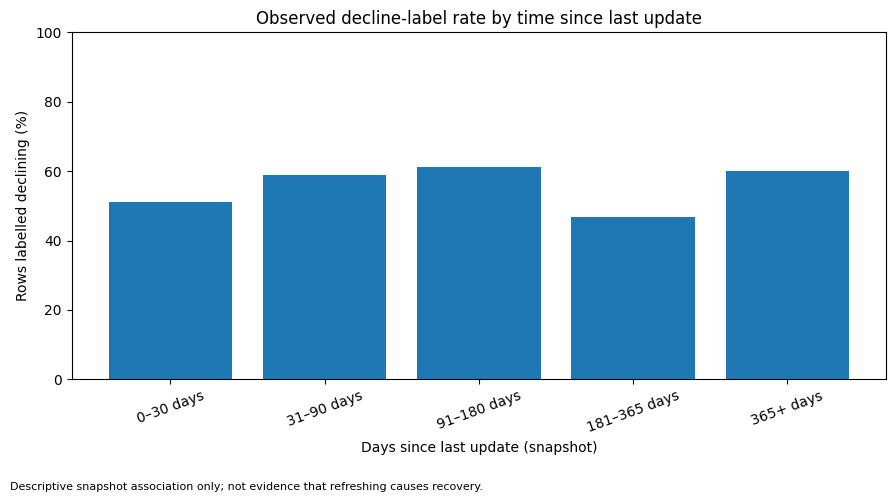

Figure saved: /mnt/data/work/figures/w07_decay_by_update_recency.png


In [4]:
# Descriptive decay check: observed decline-label prevalence by time since last update.
decay = data[["days_since_last_update", TARGET]].copy()
decay["days_since_last_update"] = pd.to_numeric(decay["days_since_last_update"], errors="coerce")
decay = decay.dropna(subset=["days_since_last_update"])
decay["update_recency_band"] = pd.cut(
    decay["days_since_last_update"],
    bins=[-np.inf, 30, 90, 180, 365, np.inf],
    labels=["0–30 days", "31–90 days", "91–180 days", "181–365 days", "365+ days"],
    right=True
)
decay_summary = decay.groupby("update_recency_band", observed=False).agg(
    rows=(TARGET, "size"), observed_decline_rate=(TARGET, "mean")
).reset_index()
decay_summary["observed_decline_rate_pct"] = (100 * decay_summary["observed_decline_rate"]).round(1)
display(decay_summary[["update_recency_band", "rows", "observed_decline_rate_pct"]])

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(decay_summary["update_recency_band"].astype(str), decay_summary["observed_decline_rate_pct"])
ax.set_title("Observed decline-label rate by time since last update")
ax.set_xlabel("Days since last update (snapshot)")
ax.set_ylabel("Rows labelled declining (%)")
ax.tick_params(axis="x", rotation=20)
ax.set_ylim(0, max(100, float(decay_summary["observed_decline_rate_pct"].max() + 10)))
fig.text(0.01, 0.01, "Descriptive snapshot association only; not evidence that refreshing causes recovery.", fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 1])
decay_fig_path = FIGURE_DIR / "w07_decay_by_update_recency.png"
fig.savefig(decay_fig_path, dpi=180, bbox_inches="tight")
plt.show()
print("Figure saved:", decay_fig_path)

## 2. Intended use and limits

**Intended users:** an SEO/content analyst or editor who understands the site, the relevant search intent, and the analytics definitions.

**Intended use:** create a small, ranked *review queue* for discussion; make triage more consistent; record why a page was reviewed; and identify where evidence is too weak. The analyst should combine the score with business context, current search results, accuracy, user needs, and editorial constraints.

**Limits that travel with every use:**
1. The dataset is a 30,000-row anonymized snapshot across 32 clients; the grouped holdout tests unseen-client transfer within this snapshot, not future-time performance.
2. Week-6 client-grouped ranking results were lower than the random-row diagnostic. The grouped holdout is the more relevant result for unseen clients, but it is still not a temporal deployment test.
3. The target is a recent trend label. Trailing 90-day aggregates are not proven to end before the target window; historical feature snapshots and later outcomes are needed to resolve temporal overlap.
4. Scores are ranking signals, not calibrated probabilities of future decline. The reason codes are transparent heuristics, not feature-attribution explanations.
5. This is not a causal intervention study. It cannot estimate the effect of refreshing content.
6. Missingness is systematic by content type; missingness indicators and imputation can encode data-collection patterns.
7. Client, niche, search engine, tracking, and content mix can change. Revalidate before transferring to a new context.

In [5]:
# Compact, reproducible quality checks and grouped-holdout ranking metrics.
def precision_at_k(y_true, scores, k):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    top_idx = np.argsort(-scores, kind="stable")[:min(k, len(y_true))]
    return float(y_true[top_idx].mean())

group_y = y.iloc[review_idx].to_numpy()
baseline_scores = (
    pd.to_numeric(review_rows["days_since_last_update"], errors="coerce").ge(180).fillna(False).astype(int)
    * pd.to_numeric(review_rows["impressions_90d"], errors="coerce").fillna(0).ge(3000).astype(int)
    * pd.to_numeric(review_rows["impressions_90d"], errors="coerce").fillna(0)
)
metrics = {
    "dataset_rows": int(len(data)),
    "client_count": int(data["client_id"].nunique()),
    "observed_decline_label_prevalence": float(y.mean()),
    "grouped_train_rows": int(len(train_idx)),
    "grouped_train_clients": int(len(train_clients)),
    "grouped_review_rows": int(len(review_idx)),
    "grouped_review_clients": int(len(review_clients)),
    "grouped_client_overlap": int(len(train_clients & review_clients)),
    "grouped_review_base_rate": float(group_y.mean()),
    "random_forest_precision_at_20": precision_at_k(group_y, review_scores, 20),
    "random_forest_precision_at_50": precision_at_k(group_y, review_scores, 50),
    "week4_rule_precision_at_20": precision_at_k(group_y, baseline_scores, 20),
    "week4_rule_precision_at_50": precision_at_k(group_y, baseline_scores, 50),
    "queue_rows": int(len(action_queue)),
    "queue_export_excludes_label": bool(TARGET not in action_queue.columns and "trend_direction" not in action_queue.columns and "trend_pct" not in action_queue.columns),
    "feature_windows_proven_temporally_prior": False,
    "causal_refresh_effect_estimated": False,
}
print(json.dumps(metrics, indent=2))
assert metrics["grouped_client_overlap"] == 0
assert metrics["queue_export_excludes_label"]
assert len(action_queue) == len(review_idx)

{
  "dataset_rows": 30000,
  "client_count": 32,
  "observed_decline_label_prevalence": 0.5420666666666667,
  "grouped_train_rows": 23837,
  "grouped_train_clients": 25,
  "grouped_review_rows": 6163,
  "grouped_review_clients": 7,
  "grouped_client_overlap": 0,
  "grouped_review_base_rate": 0.5109524582184002,
  "random_forest_precision_at_20": 0.65,
  "random_forest_precision_at_50": 0.62,
  "week4_rule_precision_at_20": 0.8,
  "week4_rule_precision_at_50": 0.7,
  "queue_rows": 6163,
  "queue_export_excludes_label": true,
  "feature_windows_proven_temporally_prior": false,
  "causal_refresh_effect_estimated": false
}


## 3. Human review + the no-go list

### Required review before an action
1. Confirm the URL/page and its business importance; check for migrations, redirects, canonical changes, or tracking anomalies.
2. Validate the apparent trend against current and prior periods using the source analytics; do not rely only on the derived label or score.
3. Check query intent, current SERP/competitors, factual accuracy, freshness, internal links, technical SEO, and content quality.
4. Read the reason codes and confirm the supporting fields are present and meaningful for this content type.
5. Record reviewer, date, evidence, proposed change, expected outcome, and whether the action was approved, deferred, or rejected.
6. After any approved edit, measure the outcome against a predeclared comparison window and account for seasonality or other changes where feasible.

### No-go: what must NOT be automated
- No automatic content rewrite, publish, delete, redirect, canonical change, or mass update.
- No automatic prioritization that overrides legal, medical, financial, safety, brand, or subject-matter review.
- No promises of traffic/revenue gains and no claim that refreshing caused a recovery from this model.
- No treating a missing metric as zero, or treating low-exposure pages as confident opportunities.
- No transfer of ranking thresholds to a new client/site without validation.
- No sending page content, identifiers, or analytics to an external generation service without approved data governance.
- No model-only decisions affecting people, regulated content, or contractual client commitments.

**Human-in-the-loop rule:** the model may order a review list; a named person owns every final action.

In [6]:
review_rules = pd.DataFrame([
    ("Identity and technical checks", "Confirm page, canonical, redirects, migration and tracking", "Required"),
    ("Evidence check", "Compare source analytics across appropriate periods and segments", "Required"),
    ("Editorial/SEO review", "Intent, SERP, accuracy, links, content quality and brand constraints", "Required"),
    ("Decision record", "Reviewer, date, evidence, action, expected outcome and disposition", "Required"),
    ("Outcome review", "Measure after approved change; consider seasonality and other changes", "Required"),
])
review_rules.columns = ["Gate", "Minimum check", "Status"]
display(review_rules)
no_go = [
    "Automatic rewriting, publishing, deleting, redirecting or mass updating",
    "Replacing legal/medical/financial/safety or subject-matter review",
    "Claiming a refresh caused recovery or guaranteeing traffic/revenue gains",
    "Treating missing values or low-exposure pages as strong evidence",
    "Transferring thresholds to new clients without validation",
]
print("No-go cases:", len(no_go))

,Gate,Minimum check,Status
0,Identity and technical checks,"Confirm page, canonical, redirects, migration ...",Required
1,Evidence check,Compare source analytics across appropriate pe...,Required
2,Editorial/SEO review,"Intent, SERP, accuracy, links, content quality...",Required
3,Decision record,"Reviewer, date, evidence, action, expected out...",Required
4,Outcome review,Measure after approved change; consider season...,Required


No-go cases: 5


## 4. Monitoring / retrain triggers

For a lightweight pilot, keep a dated record of the snapshot, feature definitions, model version, queue, reviewer decisions, and outcomes. Review monthly during the research pilot; do not run an unattended production service.

**Investigate / pause recommendations when:**
- the feature schema, tracking, metric definitions, or missingness patterns change;
- a new client/site or content type is outside the represented population;
- the observed decline-label prevalence changes materially (suggested investigation threshold: >10 percentage points from the reference snapshot, not an automatic retrain);
- grouped holdout or a future temporal validation shows Precision@20/50 materially below the frozen rule, or uncertainty is too large to support a decision;
- top-ranked items are repeatedly rejected by reviewers, or reason codes no longer match the real diagnosis;
- a properly time-forward evaluation becomes available and materially changes results.

**Retrain only when** enough new, correctly time-aligned examples exist, label definitions are stable, a client-grouped and time-forward evaluation plan is approved, and the retrained model beats a frozen baseline on predeclared metrics. Compare on the same holdout design; keep a versioned fallback baseline. A calendar date alone is not a retraining justification.

In [7]:
monitoring_triggers = pd.DataFrame([
    ("Schema / tracking change", "Any material change", "Pause queue; audit features and missingness"),
    ("Label prevalence drift", "More than 10 percentage points vs reference snapshot", "Investigate definition, population and seasonality"),
    ("Ranking utility", "P@20 or P@50 falls materially below frozen rule in a valid holdout", "Pause; inspect errors and split design"),
    ("Reviewer disagreement", "Repeated rejection or unhelpful reason codes", "Review archetypes and thresholds; do not blindly retrain"),
    ("Population shift", "New client, niche or content type outside validation coverage", "Require local validation before use"),
    ("Temporal evidence available", "Features precede a later label window", "Run a time-forward evaluation before deployment claims"),
], columns=["Trigger", "Signal", "Response"])
display(monitoring_triggers)

,Trigger,Signal,Response
0,Schema / tracking change,Any material change,Pause queue; audit features and missingness
1,Label prevalence drift,More than 10 percentage points vs reference sn...,"Investigate definition, population and seasona..."
2,Ranking utility,P@20 or P@50 falls materially below frozen rul...,Pause; inspect errors and split design
3,Reviewer disagreement,Repeated rejection or unhelpful reason codes,Review archetypes and thresholds; do not blind...
4,Population shift,"New client, niche or content type outside vali...",Require local validation before use
5,Temporal evidence available,Features precede a later label window,Run a time-forward evaluation before deploymen...


## 5. Exports for the paper

This section writes:
- `work/outputs/w07_ranked_action_queue.csv` — ranked review queue; deliberately excludes the target, sibling label fields, and actual label.
- `work/outputs/w07_decay_summary.csv` — counts and observed label rate by update-recency band for paper analysis.
- `work/outputs/w07_action_playbook_metrics.json` — reproducibility receipt and grouped-holdout ranking metrics; keep this JSON under version control.
- `work/figures/w07_decay_by_update_recency.png` — paper-ready descriptive figure.

The queue CSV is a generated data artifact and may be gitignored by repository policy. Regenerate it by running this notebook. Commit the figure and metrics JSON if permitted by the repo's data policy. Do not add raw row-level data to the paper or repository.

In [8]:
queue_path = OUTPUT_DIR / "w07_ranked_action_queue.csv"
decay_path = OUTPUT_DIR / "w07_decay_summary.csv"
metrics_path = OUTPUT_DIR / "w07_action_playbook_metrics.json"

action_queue.to_csv(queue_path, index=False)
decay_summary.to_csv(decay_path, index=False)
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

# Guardrails for the generated paper artifacts.
saved_queue = pd.read_csv(queue_path)
assert len(saved_queue) == len(action_queue)
assert "is_declining_label" not in saved_queue.columns
assert "trend_direction" not in saved_queue.columns
assert "trend_pct" not in saved_queue.columns
assert metrics["grouped_client_overlap"] == 0
for path in [queue_path, decay_path, metrics_path, decay_fig_path]:
    print(f"{path} | {path.stat().st_size:,} bytes")
print("\nTop 10 queue rows (exported fields only):")
display(saved_queue.head(10))

/mnt/data/work/outputs/w07_ranked_action_queue.csv | 1,735,156 bytes
/mnt/data/work/outputs/w07_decay_summary.csv | 260 bytes
/mnt/data/work/outputs/w07_action_playbook_metrics.json | 626 bytes
/mnt/data/work/figures/w07_decay_by_update_recency.png | 85,083 bytes

Top 10 queue rows (exported fields only):


,queue_rank,content_id,client_id,model_review_score,review_priority,reason_codes,archetype,suggested_human_action,content_type,main_intent,days_since_last_update,content_age_days,impressions_90d,clicks_90d,avg_position,ctr,engagement_rate,word_count,age_tier,freshness_tier
0,1,content_9ac61c04930e,client_8527a891e2,0.942095,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,1828,4,5.6,0.22,0.00,1504.0,181-365,91-180
1,2,content_2ba626fea4d6,client_8527a891e2,0.941754,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,360,0,7.2,0.00,0.00,1405.0,181-365,91-180
2,3,content_f55fd2d8ed04,client_4e07408562,0.936317,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,230,2237,2,1.3,0.09,0.00,1604.0,181-365,91-180
3,4,content_569475b335ab,client_4e07408562,0.930629,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,commercial,104,300,780,1,42.5,0.13,0.00,1390.0,181-365,91-180
4,5,content_1d0963b56227,client_4e07408562,0.924522,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,transactional,104,280,3445,3,39.0,0.09,20.00,1480.0,181-365,91-180
5,6,content_bb1edbf0ba6c,client_4e07408562,0.920238,REVIEW,DECAY_SIGNAL|POSITION_OPPORTUNITY,Ranking opportunity,"Review query-to-page intent, title/snippet and...",keyword article,commercial,104,280,1290,0,12.4,0.00,14.29,1432.0,181-365,91-180
6,7,content_e988c1699454,client_8527a891e2,0.918726,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,2197,0,21.5,0.00,0.00,1353.0,181-365,91-180
7,8,content_98aa0aecb1d9,client_8527a891e2,0.917484,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,104,275,5190,3,5.1,0.06,9.09,1422.0,181-365,91-180
8,9,content_500bd3907331,client_4e07408562,0.914394,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,commercial,104,230,4037,4,5.5,0.10,0.00,1294.0,181-365,91-180
9,10,content_7a6cb4857fe6,client_f369cb89fc,0.912140,REVIEW,DECAY_SIGNAL,Trend investigation,Verify the decline with a fresh time series an...,keyword article,informational,20,117,789,0,1.6,0.00,0.00,2701.0,91-180,0-30


## 6. Self-check

- [x] Ranked queue is scored on a client-grouped holdout with no client overlap.
- [x] Reason codes are defined as transparent rules, not presented as model explanations.
- [x] Archetypes map to practical, human-reviewed investigation actions.
- [x] Decay/update-recency association is shown descriptively and explicitly not causally.
- [x] Intended use and limitations are documented.
- [x] Human review gates and no-go automation cases are explicit.
- [x] Monitoring and retraining triggers are operational and not calendar-only.
- [x] Queue CSV excludes target and label-sibling fields.
- [x] Queue, decay summary, metrics JSON, and figure are exported.
- [ ] In the repository environment, rerun all cells, inspect exports, commit the notebook and figure, and commit the metrics JSON if the repository's data policy permits.

**Claim discipline:** this playbook supports review prioritization research only. It does not establish future predictive validity, a causal refresh effect, or production readiness.